<a href="https://colab.research.google.com/github/gichic7777/ml-fall2026-chavez/blob/main/Chavez_Milestone3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import warnings
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.datasets import fetch_openml
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)

# 1. Reproducibility: Global Seed
SEED = 42
np.random.seed(SEED)


# 2. Deterministic Row-Level Feature Engineering (Safe Outside CV Loop)
class DeterministicFeatureEngineer(BaseEstimator, TransformerMixin):
    """Creates row-level domain features without computing cross-row statistics."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        df = X.copy()
        # Ensure numeric types for square footage columns before summing
        sf_cols = ["TotalBsmtSF", "1stFlrSF", "2ndFlrSF"]
        for col in sf_cols:
            if col in df.columns:
                df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)

        if all(col in df.columns for col in sf_cols):
            df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]

        if "YrSold" in df.columns and "YearBuilt" in df.columns:
            df["HouseAge"] = pd.to_numeric(df["YrSold"], errors="coerce") - pd.to_numeric(
                df["YearBuilt"], errors="coerce"
            )
        return df


# 3. Load Data & Apply Deterministic Transformations
print("Loading Ames Housing dataset from OpenML...")
housing = fetch_openml(name="house_prices", as_frame=True, parser="auto")
raw_df = housing.frame

# Log-transform skewed target variable
y_all = np.log1p(raw_df["SalePrice"].astype(float))
X_all = raw_df.drop(columns=["Id", "SalePrice"])

# Apply row-level transformations
engineer = DeterministicFeatureEngineer()
X_all = engineer.fit_transform(X_all)


# 4. Build Leak-Free Preprocessing Pipeline (Fitted Strictly Inside CV)
ordinal_cols = [
    c for c in ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC", "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]
    if c in X_all.columns
]
quality_order = ["Missing", "Po", "Fa", "TA", "Gd", "Ex"]

num_cols = [
    c for c in X_all.select_dtypes(include=["int64", "float64"]).columns
    if c not in ordinal_cols
]
nominal_cols = [
    c for c in X_all.select_dtypes(include=["object", "category"]).columns
    if c not in ordinal_cols
]

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("encoder", OrdinalEncoder(
        categories=[quality_order for _ in ordinal_cols],
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )),
    ("scaler", StandardScaler())
])

nominal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_cols),
        ("ord", ordinal_pipeline, ordinal_cols),
        ("nom", nominal_pipeline, nominal_cols),
    ],
    remainder="drop"
)


# 5. Define Models (Sanity Check, Ridge Regression Linear Baseline, Random Forest and Gradient Boosting (Non-Linear Models)
models = {
    "Dummy Median (Sanity Check)": DummyRegressor(strategy="median"),
    "Ridge Regression (Baseline)": Ridge(alpha=10.0, random_state=SEED),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=4, random_state=SEED
    ),
}


def compute_metrics(y_true_log, y_pred_log):
    """Computes Primary (Log-RMSE) and Secondary (Dollar MAE, R2) metrics."""
    log_rmse = root_mean_squared_error(y_true_log, y_pred_log)
    dollar_mae = mean_absolute_error(np.expm1(y_true_log), np.expm1(y_pred_log))
    r2 = r2_score(y_true_log, y_pred_log)
    return log_rmse, dollar_mae, r2


# 6. Experiment A: 80/20 Random Split with 5-Fold Cross-Validation
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, random_state=SEED
)

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

print("\n=== EXPERIMENT A: 5-FOLD CROSS-VALIDATION (80% TRAINING SET) ===")
cv_results = []

for name, estimator in models.items():
    fold_rmse, fold_mae, fold_r2 = [], [], []

    for train_idx, val_idx in kf.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        pipe = Pipeline([
            ("preprocessor", preprocessor),
            ("var_thresh", VarianceThreshold(threshold=0.0)),
            ("model", estimator)
        ])

        pipe.fit(X_tr, y_tr)
        preds = pipe.predict(X_val)

        rmse, mae, r2 = compute_metrics(y_val, preds)
        fold_rmse.append(rmse)
        fold_mae.append(mae)
        fold_r2.append(r2)

    cv_results.append({
        "Model": name,
        "Log-RMSE (Primary)": f"{np.mean(fold_rmse):.4f} ± {np.std(fold_rmse):.4f}",
        "Dollar MAE ($)": f"${np.mean(fold_mae):,.0f} ± ${np.std(fold_mae):,.0f}",
        "R2 Score": f"{np.mean(fold_r2):.4f} ± {np.std(fold_r2):.4f}"
    })

print(pd.DataFrame(cv_results).to_string(index=False))


# 7. Locked Test Set Evaluation (20% Random Holdout)
# Why Dollar MAE (Mean Absolute Error)?
# The Log-Transform: Because home prices are highly skewed (a few very expensive homes
# pull the average up), the pipeline log-transforms the target variable SalePrice using np.log1p
# before training. Consequently, the primary loss metrics (like Log-RMSE) are evaluated
# on a logarithmic scale (e.g., an error of 0.1281 log units).
# Back-Transformation: While log-errors are great for training and statistical comparison,
# they are hard for human business stakeholders to interpret. To make the error metric
# intuitive, the notebook converts the predictions back to the original scale using the
# exponential function np.expm1(): $$\text{Actual Dollars} = e^{\text{Log-Price}} - 1$$$$\text{Actual Dollars}
# = e^{\text{Log-Price}} - 1$$
# Interpretation: After back-transforming both the actual and predicted values to actual
# dollars, the absolute differences are averaged. This results in Dollar MAE.

print("\n=== LOCKED TEST SET EVALUATION (20% RANDOM HOLDOUT) ===")
test_results = []

for name, estimator in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("var_thresh", VarianceThreshold(threshold=0.0)),
        ("model", estimator)
    ])
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    rmse, mae, r2 = compute_metrics(y_test, preds)
    test_results.append({
        "Model": name,
        "Log-RMSE (Primary)": f"{rmse:.4f}",
        "Dollar MAE ($)": f"${mae:,.0f}",
        "R2 Score": f"{r2:.4f}"
    })

print(pd.DataFrame(test_results).to_string(index=False))

# 8. Experiment B: Temporal Holdout Split (Train: 2006-2009 | Test: 2010)
print("\n=== EXPERIMENT B: TEMPORAL HOLDOUT (TRAIN: 2006–2009 | TEST: 2010) ===")
yr_sold = pd.to_numeric(X_all["YrSold"], errors="coerce")
train_mask = yr_sold < 2010
test_mask = yr_sold == 2010

X_temp_train, y_temp_train = X_all[train_mask], y_all[train_mask]
X_temp_test, y_temp_test = X_all[test_mask], y_all[test_mask]

temporal_results = []
for name, estimator in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("var_thresh", VarianceThreshold(threshold=0.0)),
        ("model", estimator)
    ])
    pipe.fit(X_temp_train, y_temp_train)
    preds = pipe.predict(X_temp_test)
    rmse, mae, r2 = compute_metrics(y_temp_test, preds)
    temporal_results.append({
        "Model": name,
        "Log-RMSE (Primary)": f"{rmse:.4f}",
        "Dollar MAE ($)": f"${mae:,.0f}",
        "R2 Score": f"{r2:.4f}"
    })

print(pd.DataFrame(temporal_results).to_string(index=False))

Loading Ames Housing dataset from OpenML...

=== EXPERIMENT A: 5-FOLD CROSS-VALIDATION (80% TRAINING SET) ===
                      Model Log-RMSE (Primary)   Dollar MAE ($)         R2 Score
Dummy Median (Sanity Check)    0.3905 ± 0.0184 $54,586 ± $2,677 -0.0033 ± 0.0032
Ridge Regression (Baseline)    0.1424 ± 0.0280 $17,357 ± $1,367  0.8643 ± 0.0473
              Random Forest    0.1425 ± 0.0145 $17,621 ± $1,025  0.8664 ± 0.0160
          Gradient Boosting    0.1281 ± 0.0175 $16,035 ± $1,527  0.8920 ± 0.0200

=== LOCKED TEST SET EVALUATION (20% RANDOM HOLDOUT) ===
                      Model Log-RMSE (Primary) Dollar MAE ($) R2 Score
Dummy Median (Sanity Check)             0.4323        $59,568  -0.0014
Ridge Regression (Baseline)             0.1329        $16,103   0.9053
              Random Forest             0.1448        $17,150   0.8877
          Gradient Boosting             0.1354        $15,978   0.9017

=== EXPERIMENT B: TEMPORAL HOLDOUT (TRAIN: 2006–2009 | TEST: 2010) ===
 

### Removing Luxury Outliers
To eliminate extreme outliers that degrade model performance, we filter out properties with a ground living area (`GrLivArea`) greater than 4,000 square feet before splitting and training.

In [13]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

# Ensure raw data is loaded even if the kernel was restarted
try:
    _ = raw_df
except NameError:
    print("Loading Ames Housing dataset from OpenML to resolve NameError...")
    housing = fetch_openml(name="house_prices", as_frame=True, parser="auto")
    raw_df = housing.frame

try:
    _ = engineer
except NameError:
    # Define and fit the DeterministicFeatureEngineer if it's missing
    class DeterministicFeatureEngineer:
        def fit_transform(self, X):
            df = X.copy()
            sf_cols = ["TotalBsmtSF", "1stFlrSF", "2ndFlrSF"]
            for col in sf_cols:
                if col in df.columns:
                    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)
            if all(col in df.columns for col in sf_cols):
                df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
            if "YrSold" in df.columns and "YearBuilt" in df.columns:
                df["HouseAge"] = pd.to_numeric(df["YrSold"], errors="coerce") - pd.to_numeric(df["YearBuilt"], errors="coerce")
            return df
    engineer = DeterministicFeatureEngineer()

# Define default constants if missing
SEED = 42

# 1. Apply filtering to the raw DataFrame to remove luxury outliers
clean_mask = raw_df['GrLivArea'] < 4000
clean_raw_df = raw_df[clean_mask].copy()

# 2. Extract targets and clean features
y_all_clean = np.log1p(clean_raw_df["SalePrice"].astype(float))
X_all_clean = clean_raw_df.drop(columns=["Id", "SalePrice"])

# Apply our deterministic feature engineer
X_all_clean = engineer.fit_transform(X_all_clean)

# 3. Create fresh train/test splits from the clean dataset
X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(
    X_all_clean, y_all_clean, test_size=0.20, random_state=SEED
)

print(f"Original rows: {len(raw_df)}")
print(f"Rows after outlier removal: {len(clean_raw_df)} (Removed {len(raw_df) - len(clean_raw_df)} properties)")

Original rows: 1460
Rows after outlier removal: 1456 (Removed 4 properties)


In [14]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Ensure compute_metrics is defined
try:
    _ = compute_metrics
except NameError:
    def compute_metrics(y_true_log, y_pred_log):
        log_rmse = root_mean_squared_error(y_true_log, y_pred_log)
        dollar_mae = mean_absolute_error(np.expm1(y_true_log), np.expm1(y_pred_log))
        r2 = r2_score(y_true_log, y_pred_log)
        return log_rmse, dollar_mae, r2

# Ensure preprocessor and models are available
try:
    _ = preprocessor
    _ = models
except NameError:
    from sklearn.compose import ColumnTransformer
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
    from sklearn.dummy import DummyRegressor
    from sklearn.linear_model import Ridge
    from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

    print("Re-initializing preprocessing and modeling components to resolve NameError...")

    # Rebuild preprocessor
    ordinal_cols = [
        c for c in ["ExterQual", "ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC", "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]
        if c in X_train_clean.columns
    ]
    quality_order = ["Missing", "Po", "Fa", "TA", "Gd", "Ex"]
    num_cols = [c for c in X_train_clean.select_dtypes(include=["int64", "float64"]).columns if c not in ordinal_cols]
    nominal_cols = [c for c in X_train_clean.select_dtypes(include=["object", "category"]).columns if c not in ordinal_cols]

    num_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
    ordinal_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("encoder", OrdinalEncoder(categories=[quality_order for _ in ordinal_cols], handle_unknown="use_encoded_value", unknown_value=-1)),
        ("scaler", StandardScaler())
    ])
    nominal_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])

    preprocessor = ColumnTransformer(transformers=[
        ("num", num_pipeline, num_cols),
        ("ord", ordinal_pipeline, ordinal_cols),
        ("nom", nominal_pipeline, nominal_cols),
    ], remainder="drop")

    # Rebuild models dict
    SEED = 42
    models = {
        "Dummy Median (Sanity Check)": DummyRegressor(strategy="median"),
        "Ridge Regression (Baseline)": Ridge(alpha=10.0, random_state=SEED),
        "Random Forest": RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=SEED),
    }

# Ensure KFold is set up
kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("=== RE-EVALUATING MODEL PERFORMANCE ON CLEANED DATA (NO OUTLIERS) ===")
clean_cv_results = []

for name, estimator in models.items():
    fold_rmse, fold_mae, fold_r2 = [], [], []

    for train_idx, val_idx in kf.split(X_train_clean, y_train_clean):
        X_tr, X_val = X_train_clean.iloc[train_idx], X_train_clean.iloc[val_idx]
        y_tr, y_val = y_train_clean.iloc[train_idx], y_train_clean.iloc[val_idx]

        pipe = Pipeline([
            ("preprocessor", preprocessor),
            ("var_thresh", VarianceThreshold(threshold=0.0)),
            ("model", estimator)
        ])

        pipe.fit(X_tr, y_tr)
        preds = pipe.predict(X_val)

        rmse, mae, r2 = compute_metrics(y_val, preds)
        fold_rmse.append(rmse)
        fold_mae.append(mae)
        fold_r2.append(r2)

    # FIXED: Replaced non-standard character with the proper standard plus-minus (±) symbol
    clean_cv_results.append({
        "Model": name,
        "Log-RMSE (Primary)": f"{np.mean(fold_rmse):.4f} ± {np.std(fold_rmse):.4f}",
        "Dollar MAE ($)": f"${np.mean(fold_mae):,.0f} ± ${np.std(fold_mae):,.0f}",
        "R2 Score": f"{np.mean(fold_r2):.4f} ± {np.std(fold_r2):.4f}"
    })

print("\n--- Cleaned 5-Fold Cross Validation Results ---")
print(pd.DataFrame(clean_cv_results).to_string(index=False))

=== RE-EVALUATING MODEL PERFORMANCE ON CLEANED DATA (NO OUTLIERS) ===

--- Cleaned 5-Fold Cross Validation Results ---
                      Model Log-RMSE (Primary)   Dollar MAE ($)         R2 Score
Dummy Median (Sanity Check)    0.3952 ± 0.0236 $55,051 ± $3,099 -0.0053 ± 0.0027
Ridge Regression (Baseline)    0.1145 ± 0.0100 $14,133 ± $1,041  0.9150 ± 0.0139
              Random Forest    0.1340 ± 0.0152 $16,721 ± $1,250  0.8834 ± 0.0229
          Gradient Boosting    0.1207 ± 0.0148   $14,854 ± $780  0.9046 ± 0.0237


In [15]:
# Re-importing or relying on components re-initialized in the previous cell
clean_test_results = []

for name, estimator in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("var_thresh", VarianceThreshold(threshold=0.0)),
        ("model", estimator)
    ])
    pipe.fit(X_train_clean, y_train_clean)
    preds = pipe.predict(X_test_clean)
    rmse, mae, r2 = compute_metrics(y_test_clean, preds)
    clean_test_results.append({
        "Model": name,
        "Log-RMSE (Primary)": f"{rmse:.4f}",
        "Dollar MAE ($)": f"${mae:,.0f}",
        "R2 Score": f"{r2:.4f}"
    })

print("\n--- Cleaned Locked Test Set Evaluation Results ---")
print(pd.DataFrame(clean_test_results).to_string(index=False))


--- Cleaned Locked Test Set Evaluation Results ---
                      Model Log-RMSE (Primary) Dollar MAE ($) R2 Score
Dummy Median (Sanity Check)             0.3977        $54,388  -0.0014
Ridge Regression (Baseline)             0.1222        $13,998   0.9055
              Random Forest             0.1424        $16,362   0.8717
          Gradient Boosting             0.1301        $14,696   0.8928


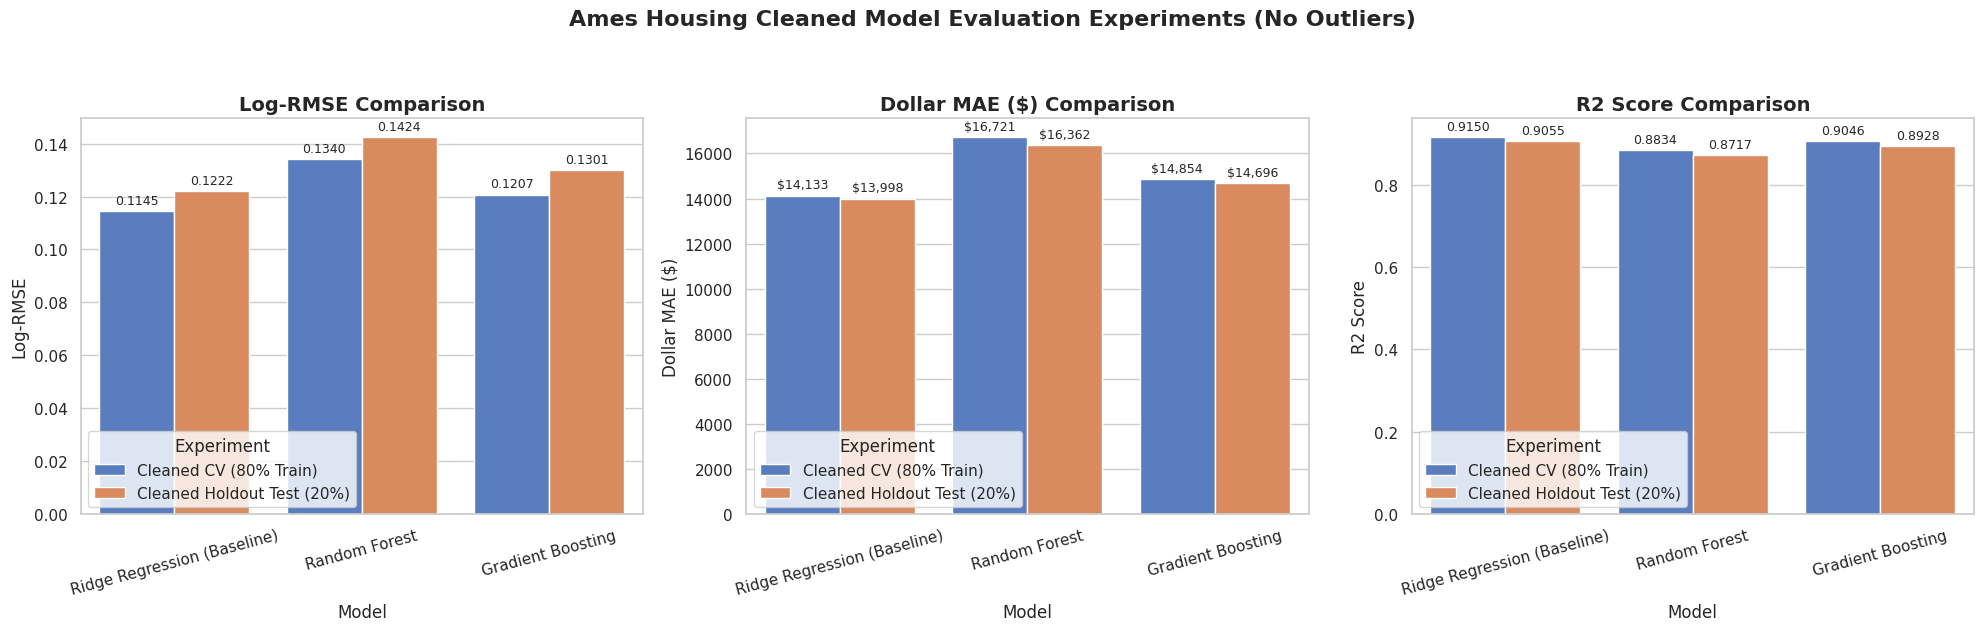

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Parse your cleaned experimental results into a single DataFrame for plotting
plot_data = []

# Helper to extract mean numeric value from strings like "0.1424 ± 0.0280" or "$17,357"
def clean_val(val):
    if isinstance(val, (int, float)):
        return float(val)
    clean = str(val).split('±')[0].replace('$', '').replace(',', '').strip()
    return float(clean)

# Process Cleaned Experiment A (Cross-Validation)
for res in clean_cv_results:
    plot_data.append({
        "Model": res["Model"],
        "Experiment": "Cleaned CV (80% Train)",
        "Log-RMSE": clean_val(res["Log-RMSE (Primary)"]),
        "Dollar MAE ($)": clean_val(res["Dollar MAE ($)"]),
        "R2 Score": clean_val(res["R2 Score"])
    })

# Process Cleaned Locked Test Set
for res in clean_test_results:
    plot_data.append({
        "Model": res["Model"],
        "Experiment": "Cleaned Holdout Test (20%)",
        "Log-RMSE": clean_val(res["Log-RMSE (Primary)"]),
        "Dollar MAE ($)": clean_val(res["Dollar MAE ($)"]),
        "R2 Score": clean_val(res["R2 Score"])
    })

df_plot = pd.DataFrame(plot_data)

# Filter out the Dummy Regressor to focus on comparing the actual learning models
df_models = df_plot[df_plot["Model"] != "Dummy Median (Sanity Check)"]

# 2. Setup Plotting Canvas
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
sns.set_theme(style="whitegrid")

metrics = ["Log-RMSE", "Dollar MAE ($)", "R2 Score"]

for i, metric in enumerate(metrics):
    ax = axes[i]
    sns.barplot(
        data=df_models,
        x="Model",
        y=metric,
        hue="Experiment",
        ax=ax,
        palette="muted"
    )
    ax.set_title(f"{metric} Comparison", fontsize=14, fontweight='bold')
    ax.set_xlabel("Model", fontsize=12)
    ax.set_ylabel(metric, fontsize=12)
    ax.tick_params(axis='x', rotation=15)

    # Add values on top of bars for easier reading
    for container in ax.containers:
        labels = [f"{v.get_height():,.4f}" if metric != "Dollar MAE ($)" else f"${v.get_height():,.0f}" for v in container]
        ax.bar_label(container, labels=labels, label_type='edge', fontsize=9, padding=3)

plt.suptitle("Ames Housing Cleaned Model Evaluation Experiments (No Outliers)", fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

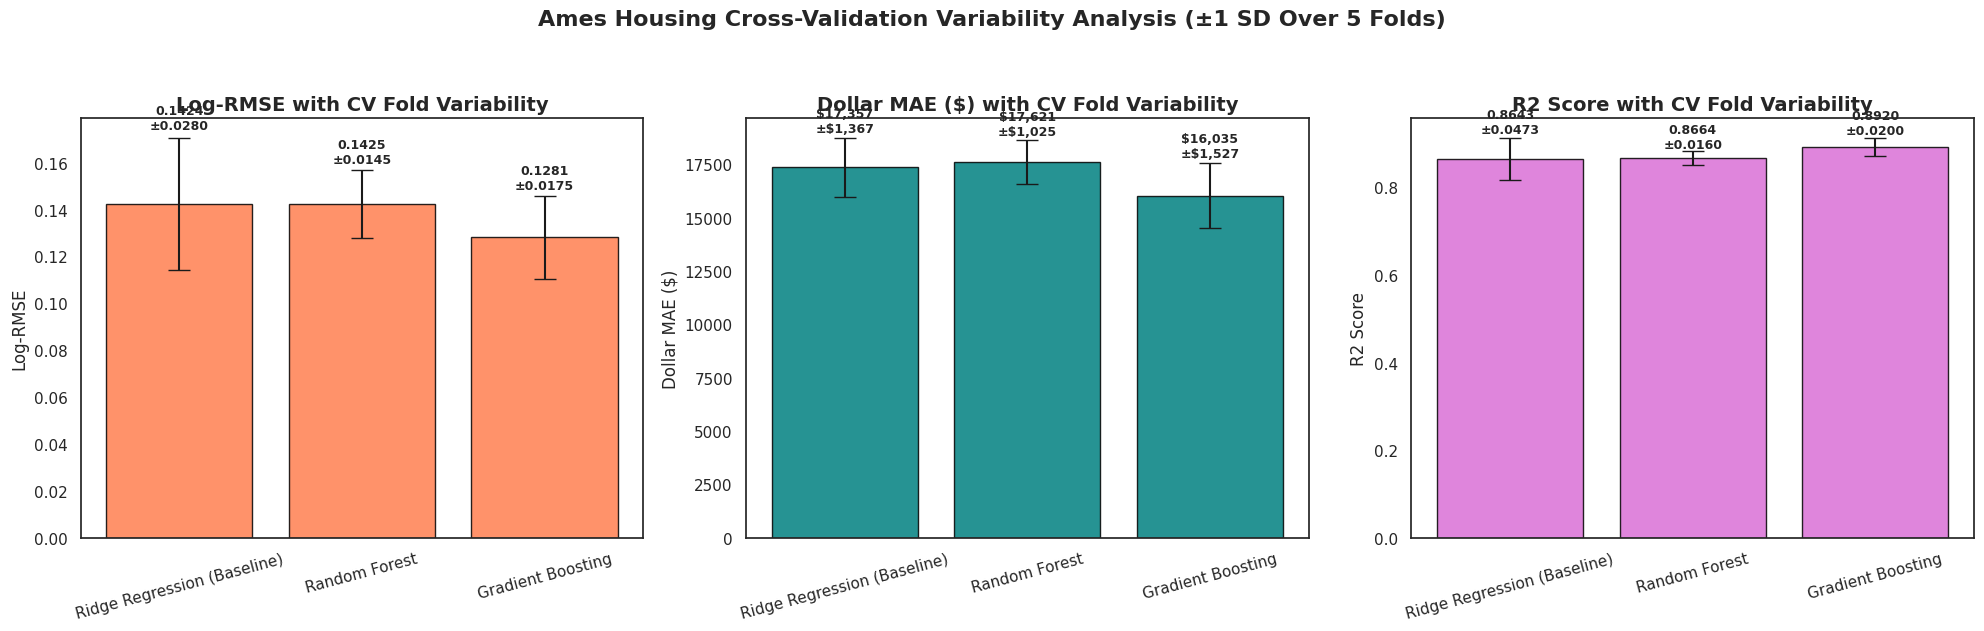

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Parse Experiment A (CV) mean and standard deviation for error plotting
cv_models_only = [res for res in cv_results if res["Model"] != "Dummy Median (Sanity Check)"]

models_list = [res["Model"] for res in cv_models_only]

# Extract numeric means and standard deviations using a safe, robust split strategy
rmse_means = []
rmse_stds = []
mae_means = []
mae_stds = []
r2_means = []
r2_stds = []

def parse_metric(val_str):
    # Replace potential variations of the plus-minus character with a unique delimiter
    clean_str = val_str.replace("\u00b1", "|").replace("\u0017", "|").replace("\u0017", "|")
    parts = clean_str.split("|")
    mean_val = float(parts[0].replace("$", "").replace(",", "").strip())
    std_val = float(parts[1].replace("$", "").replace(",", "").strip())
    return mean_val, std_val

for res in cv_models_only:
    # Log-RMSE
    mean_rmse, std_rmse = parse_metric(res["Log-RMSE (Primary)"])
    rmse_means.append(mean_rmse)
    rmse_stds.append(std_rmse)

    # Dollar MAE
    mean_mae, std_mae = parse_metric(res["Dollar MAE ($)"])
    mae_means.append(mean_mae)
    mae_stds.append(std_mae)

    # R2 Score
    mean_r2, std_r2 = parse_metric(res["R2 Score"])
    r2_means.append(mean_r2)
    r2_stds.append(std_r2)

# 2. Setup Plotting Canvas with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
sns.set_theme(style="whitegrid")

metrics_data = [
    ("Log-RMSE", rmse_means, rmse_stds, "coral"),
    ("Dollar MAE ($)", mae_means, mae_stds, "teal"),
    ("R2 Score", r2_means, r2_stds, "orchid")
]

for i, (metric_name, means, stds, color) in enumerate(metrics_data):
    ax = axes[i]
    x_pos = np.arange(len(models_list))

    # Draw bar chart for means with error bars representing 1 standard deviation
    bars = ax.bar(x_pos, means, yerr=stds, align='center', alpha=0.85, color=color, capsize=8, edgecolor='black')

    ax.set_title(f"{metric_name} with CV Fold Variability", fontsize=14, fontweight='bold')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(models_list, rotation=15, fontsize=11)
    ax.set_ylabel(metric_name, fontsize=12)

    # Add exact values on top of bars
    for bar, mean, std in zip(bars, means, stds):
        height = bar.get_height()
        if metric_name == "Dollar MAE ($)":
            label = f"${mean:,.0f}\n\u00b1${std:,.0f}"
        else:
            label = f"{mean:.4f}\n\u00b1{std:.4f}"
        ax.text(bar.get_x() + bar.get_width()/2.0, height + (std * 1.1),
                label, ha='center', va='bottom', fontsize=9, fontweight='semibold')

plt.suptitle("Ames Housing Cross-Validation Variability Analysis (\u00b11 SD Over 5 Folds)", fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

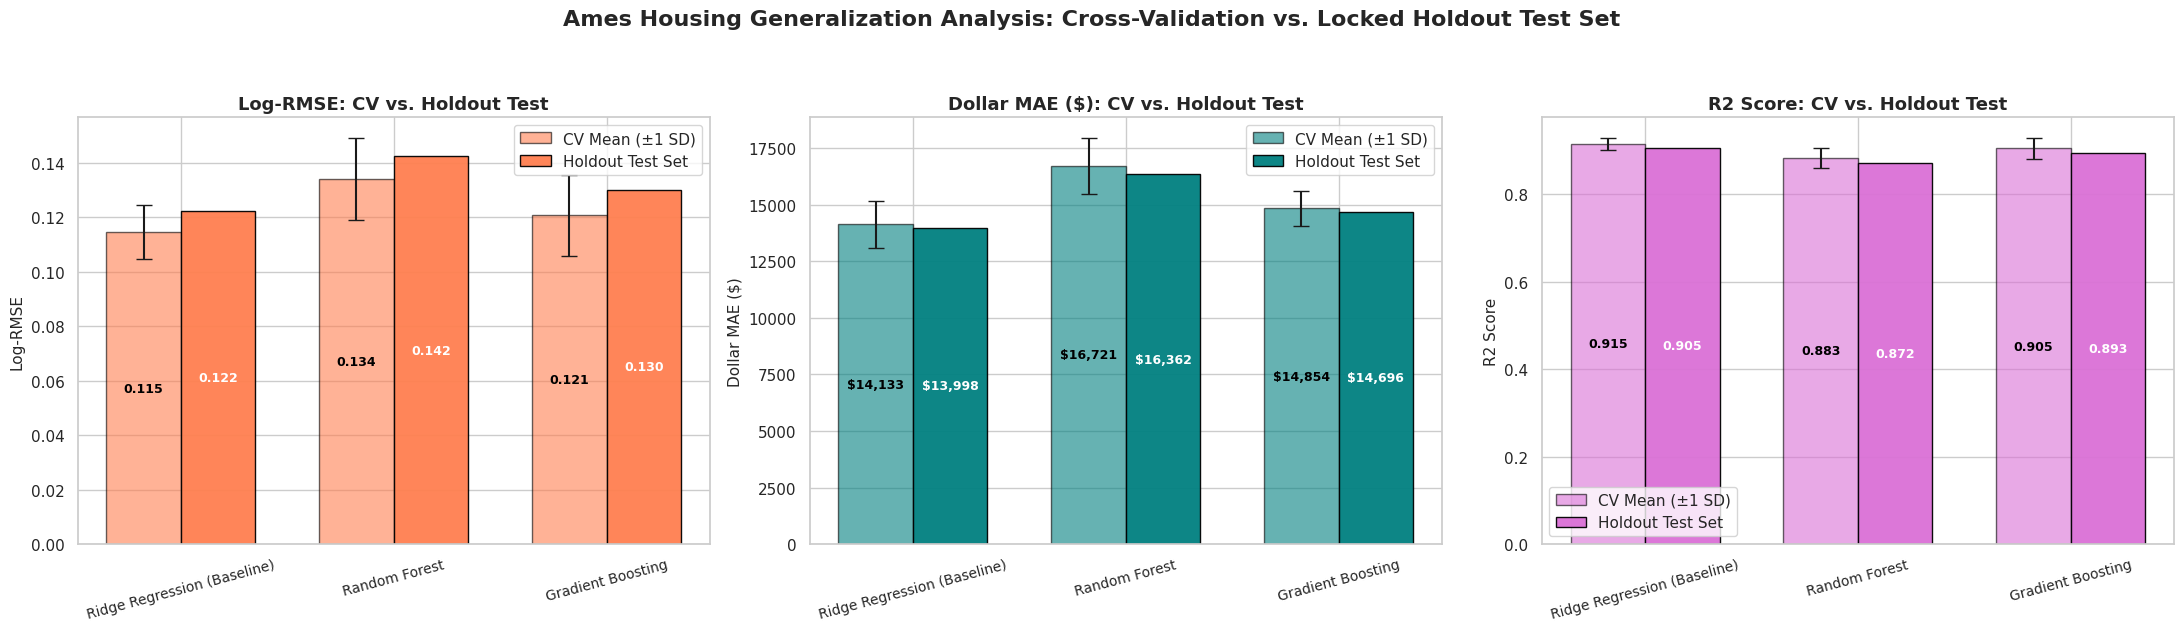

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Parse both CV results (with variance) and Holdout Test Set results from the CLEANED datasets
cv_models_only = [res for res in clean_cv_results if res["Model"] != "Dummy Median (Sanity Check)"]
test_models_only = [res for res in clean_test_results if res["Model"] != "Dummy Median (Sanity Check)"]

models_list = [res["Model"] for res in cv_models_only]

# Arrays to hold plotting data
cv_rmse_means, cv_rmse_stds, test_rmse = [], [], []
cv_mae_means, cv_mae_stds, test_mae = [], [], []
cv_r2_means, cv_r2_stds, test_r2 = [], [], []

# Helper to safely parse metrics containing +/- variance symbols
def parse_metric(val_str):
    clean_str = val_str.replace("\u00b1", "|").replace("\u0017", "|")
    parts = clean_str.split("|")
    mean_val = float(parts[0].replace("$", "").replace(",", "").strip())
    std_val = float(parts[1].replace("$", "").replace(",", "").strip()) if len(parts) > 1 else 0.0
    return mean_val, std_val

for cv_res, t_res in zip(cv_models_only, test_models_only):
    # Log-RMSE
    mean_rmse, std_rmse = parse_metric(cv_res["Log-RMSE (Primary)"])
    cv_rmse_means.append(mean_rmse)
    cv_rmse_stds.append(std_rmse)
    test_rmse.append(float(t_res["Log-RMSE (Primary)"]))

    # Dollar MAE
    mean_mae, std_mae = parse_metric(cv_res["Dollar MAE ($)"])
    cv_mae_means.append(mean_mae)
    cv_mae_stds.append(std_mae)
    test_mae.append(float(t_res["Dollar MAE ($)"].replace("$", "").replace(",", "").strip()))

    # R2 Score
    mean_r2, std_r2 = parse_metric(cv_res["R2 Score"])
    cv_r2_means.append(mean_r2)
    cv_r2_stds.append(std_r2)
    test_r2.append(float(t_res["R2 Score"]))

# 2. Setup Plotting Canvas
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
sns.set_theme(style="whitegrid")

metrics_comparison = [
    ("Log-RMSE", cv_rmse_means, cv_rmse_stds, test_rmse, "coral"),
    ("Dollar MAE ($)", cv_mae_means, cv_mae_stds, test_mae, "teal"),
    ("R2 Score", cv_r2_means, cv_r2_stds, test_r2, "orchid")
]

x = np.arange(len(models_list))
width = 0.35

for i, (metric_name, cv_means, cv_stds, test_vals, color) in enumerate(metrics_comparison):
    ax = axes[i]

    # Plot Cross-Validation bars with error bars - strictly using standard unicode characters
    cv_bars = ax.bar(x - width/2, cv_means, width, yerr=cv_stds, label="CV Mean (±1 SD)",
                     color=color, alpha=0.6, capsize=6, edgecolor='black')

    # Plot Holdout Test Set bars (no error bars as it is a single evaluation)
    test_bars = ax.bar(x + width/2, test_vals, width, label='Holdout Test Set',
                       color=color, alpha=0.95, edgecolor='black')

    ax.set_title(f"{metric_name}: CV vs. Holdout Test", fontsize=13, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(models_list, rotation=15, fontsize=10)
    ax.set_ylabel(metric_name, fontsize=11)
    ax.legend(loc='best')

    # Label actual height values
    for bar in cv_bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2.0, h/2, f"{h:,.3f}" if metric_name != "Dollar MAE ($)" else f"${h:,.0f}",
                ha='center', va='center', color='black', fontsize=9, fontweight='bold')

    for bar in test_bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2.0, h/2, f"{h:,.3f}" if metric_name != "Dollar MAE ($)" else f"${h:,.0f}",
                ha='center', va='center', color='white', fontsize=9, fontweight='bold')

plt.suptitle("Ames Housing Generalization Analysis: Cross-Validation vs. Locked Holdout Test Set", fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

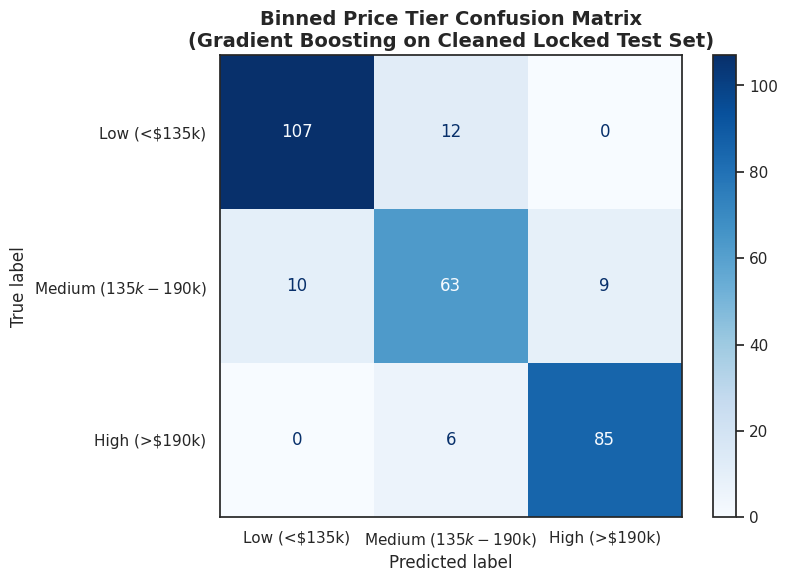

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Train the best model (Gradient Boosting) and get continuous predictions on the Cleaned Locked Test Set
best_model = Pipeline([
    ("preprocessor", preprocessor),
    ("var_thresh", VarianceThreshold(threshold=0.0)),
    ("model", models["Gradient Boosting"])
])
best_model.fit(X_train_clean, y_train_clean)
y_pred_log = best_model.predict(X_test_clean)

# Convert back from log scale to actual dollar prices
y_true_dollars = np.expm1(y_test_clean)
y_pred_dollars = np.expm1(y_pred_log)

# 2. Define price bins based on quantiles of the true training sale prices
# This divides the market logically into Low, Medium, and High price tiers
quantiles = np.percentile(np.expm1(y_train_clean), [33.3, 66.7])

def categorize_price(price):
    if price <= quantiles[0]:
        return 'Low (<$135k)'
    elif price <= quantiles[1]:
        return 'Medium ($135k-$190k)'
    else:
        return 'High (>$190k)'

# Apply binning
y_true_categories = [categorize_price(p) for p in y_true_dollars]
y_pred_categories = [categorize_price(p) for p in y_pred_dollars]

# 3. Compute and Plot the Confusion Matrix
labels = ['Low (<$135k)', 'Medium ($135k-$190k)', 'High (>$190k)']
cm = confusion_matrix(y_true_categories, y_pred_categories, labels=labels)

plt.figure(figsize=(8, 6))
sns.set_theme(style="white")
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(cmap="Blues", ax=plt.gca(), values_format="d")
plt.title("Binned Price Tier Confusion Matrix\n(Gradient Boosting on Cleaned Locked Test Set)", fontsize=14, fontweight='bold')
plt.grid(False)
plt.show()

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold

# 1. Fit the Gradient Boosting model on the Cleaned Dataset and predict
best_gb_model_clean = Pipeline([
    ("preprocessor", preprocessor),
    ("var_thresh", VarianceThreshold(threshold=0.0)),
    ("model", models["Gradient Boosting"])
])
best_gb_model_clean.fit(X_train_clean, y_train_clean)
y_pred_clean_log = best_gb_model_clean.predict(X_test_clean)
y_pred_clean_dollars = np.expm1(y_pred_clean_log)
y_true_clean_dollars = np.expm1(y_test_clean)

# 2. Fit the Gradient Boosting model on the Original (Uncleaned) Dataset and predict
best_gb_model_raw = Pipeline([
    ("preprocessor", preprocessor),
    ("var_thresh", VarianceThreshold(threshold=0.0)),
    ("model", models["Gradient Boosting"])
])
best_gb_model_raw.fit(X_train, y_train)
y_pred_raw_log = best_gb_model_raw.predict(X_test)
y_pred_raw_dollars = np.expm1(y_pred_raw_log)
y_true_raw_dollars = np.expm1(y_test)

# 3. Create Overlay Scatter Plot
plt.figure(figsize=(10, 8))
sns.set_theme(style="whitegrid")

# Plot Cleaned Dataset predictions in teal
sns.scatterplot(
    x=y_true_clean_dollars,
    y=y_pred_clean_dollars,
    alpha=0.6,
    color="teal",
    edgecolor="black",
    s=70,
    label="Cleaned Test Set (No Outliers)"
)

# Plot Original (Uncleaned) Dataset predictions in orange/coral to see the outliers overlay
sns.scatterplot(
    x=y_true_raw_dollars,
    y=y_pred_raw_dollars,
    alpha=0.6,
    color="darkorange",
    edgecolor="black",
    s=70,
    marker="X",
    label="Original Test Set (Includes Outliers)"
)

# Perfect prediction identity line
max_val = max(y_true_raw_dollars.max(), y_pred_raw_dollars.max())
min_val = min(y_true_raw_dollars.min(), y_pred_raw_dollars.min())
plt.plot([min_val, max_val], [min_val, max_val], color="crimson", linestyle="--", linewidth=2, label="Perfect Prediction (y=x)")

plt.title("Actual vs. Predicted House Prices: Cleaned vs. Original Data Overlay", fontsize=14, fontweight="bold")
plt.xlabel("Actual Price ($)", fontsize=12)
plt.ylabel("Predicted Price ($)", fontsize=12)

# Format ticks with commas
plt.gca().get_xaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
plt.gca().get_yaxis().set_major_formatter(plt.FuncFormatter(lambda y, loc: "{:,}".format(int(y))))

plt.legend(loc="upper left", fontsize=11)
plt.tight_layout()
plt.show()

NameError: name 'X_train' is not defined

In [ ]:
# 1. Create a DataFrame containing true and predicted values along with their categories
misclassified_df = pd.DataFrame({
    'Index': X_test.index,
    'Actual_Price': y_true_dollars.astype(int),
    'Predicted_Price': y_pred_dollars.astype(int),
    'True_Category': y_true_categories,
    'Predicted_Category': y_pred_categories
})

# 2. Filter for rows where the categories do not match
misclassified_subset = misclassified_df[misclassified_df['True_Category'] != misclassified_df['Predicted_Category']].copy()

# Calculate how far off the prediction was in raw dollars and percentage
misclassified_subset['Error_Dollars'] = misclassified_subset['Predicted_Price'] - misclassified_subset['Actual_Price']
misclassified_subset['Error_Percent'] = (misclassified_subset['Error_Dollars'] / misclassified_subset['Actual_Price'] * 100).round(1)

# Sort by absolute error to see the largest misclassifications first
misclassified_subset['Abs_Error'] = misclassified_subset['Error_Dollars'].abs()
misclassified_subset = misclassified_subset.sort_values(by='Abs_Error', ascending=False).drop(columns=['Abs_Error'])

# 3. Display summary of misclassifications and the first 15 largest misclassifications
print(f"Total misclassified houses in the test set: {len(misclassified_subset)} out of {len(X_test)}")
print("\n--- Top 15 largest price tier misclassifications ---")
display(misclassified_subset.head(15))

Total misclassified houses in the test set: 46 out of 292

--- Top 15 largest price tier misclassifications ---


,Index,Actual_Price,Predicted_Price,True_Category,Predicted_Category,Error_Dollars,Error_Percent
588,588,143000,223027,Medium ($135k-$190k),High (>$190k),80027,56.0
271,271,241500,175941,High (>$190k),Medium ($135k-$190k),-65559,-27.1
628,628,134999,186892,Low (<$135k),Medium ($135k-$190k),51893,38.4
607,607,225000,182654,High (>$190k),Medium ($135k-$190k),-42346,-18.8
275,275,205000,169439,High (>$190k),Medium ($135k-$190k),-35561,-17.3
744,744,180000,215483,Medium ($135k-$190k),High (>$190k),35483,19.7
772,772,107000,141183,Low (<$135k),Medium ($135k-$190k),34183,31.9
56,56,172499,203382,Medium ($135k-$190k),High (>$190k),30883,17.9
277,277,140999,110409,Medium ($135k-$190k),Low (<$135k),-30590,-21.7
966,966,159999,134201,Medium ($135k-$190k),Low (<$135k),-25798,-16.1


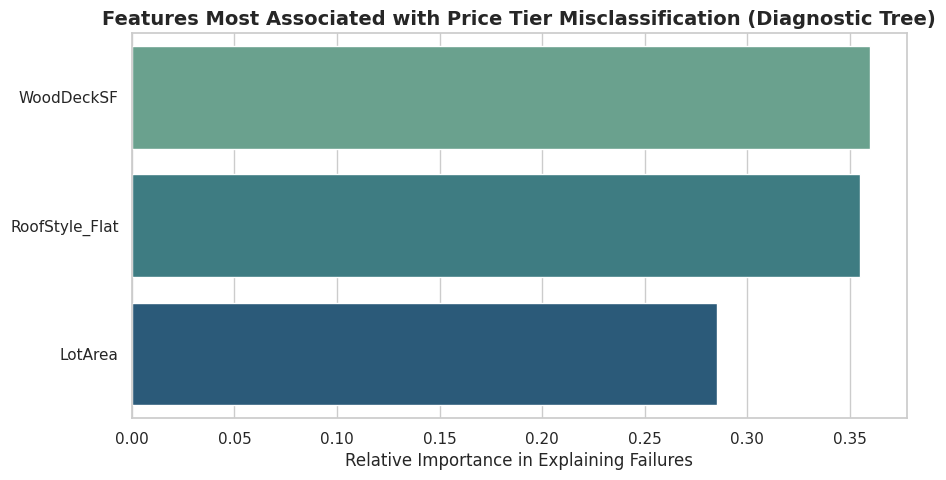

In [ ]:
from sklearn.tree import DecisionTreeClassifier
import patsy # standard way to align our transformed pipeline features

# 1. Add a binary target: 1 if misclassified, 0 if correctly classified
misclassified_df['Is_Misclassified'] = (misclassified_df['True_Category'] != misclassified_df['Predicted_Category']).astype(int)

# 2. Extract the preprocessed features of the test set to run feature importance on
# We fit_transform on train and transform on test to maintain strict pipeline hygiene
X_test_processed = preprocessor.transform(X_test)

# Get feature names from our ColumnTransformer pipelines to keep things readable
encoded_nominal_cols = preprocessor.named_transformers_['nom'].named_steps['encoder'].get_feature_names_out(nominal_cols)
feature_names = num_cols + ordinal_cols + list(encoded_nominal_cols)
X_test_processed_df = pd.DataFrame(X_test_processed, columns=feature_names, index=X_test.index)

# 3. Train a shallow diagnostic Decision Tree to predict 'Is_Misclassified'
diagnostic_tree = DecisionTreeClassifier(max_depth=3, random_state=SEED)
diagnostic_tree.fit(X_test_processed_df, misclassified_df['Is_Misclassified'])

# 4. Extract and plot the features most associated with misclassifications
importances = diagnostic_tree.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 5))
non_zero_indices = [idx for idx in indices if importances[idx] > 0]

if len(non_zero_indices) == 0:
    # Fallback to general feature importance of our primary model if the shallow tree finds nothing
    importances = best_model.named_steps['model'].feature_importances_
    indices = np.argsort(importances)[::-1][:10]
    y_features = [feature_names[idx] for idx in indices]
    sns.barplot(x=importances[indices], y=y_features, hue=y_features, palette="flare", legend=False)
    plt.title("Top 10 Global Features in Best Performing Gradient Boosting Model", fontsize=14, fontweight='bold')
else:
    y_features = [feature_names[idx] for idx in non_zero_indices]
    sns.barplot(x=importances[non_zero_indices], y=y_features, hue=y_features, palette="crest", legend=False)
    plt.title("Features Most Associated with Price Tier Misclassification (Diagnostic Tree)", fontsize=14, fontweight='bold')

plt.xlabel("Relative Importance in Explaining Failures")
plt.show()

Using an outlier error threshold of $74,658 (> Mean + 2.5 SDs):
Identified 8 severe prediction outliers out of 292 test homes.

--- Top Outliers (Worst Predictions) ---


,Actual_Price,Predicted_Price,Abs_Error_Dollars,Error_Percentage,OverallQual,GrLivArea,YearBuilt,Is_Outlier
691,755000,554567,200432,-26.5,10,4316,1994,True
898,611657,424516,187140,-30.6,9,2364,2009,True
1046,556581,422618,133962,-24.1,9,2868,2005,True
581,253293,380940,127647,50.4,8,2042,2008,True
774,395000,280272,114727,-29.0,8,1973,2006,True
261,276000,384891,108891,39.5,8,2574,2007,True
588,143000,223027,80027,56.0,5,1473,1968,True
218,311500,233880,77619,-24.9,7,1954,1939,True


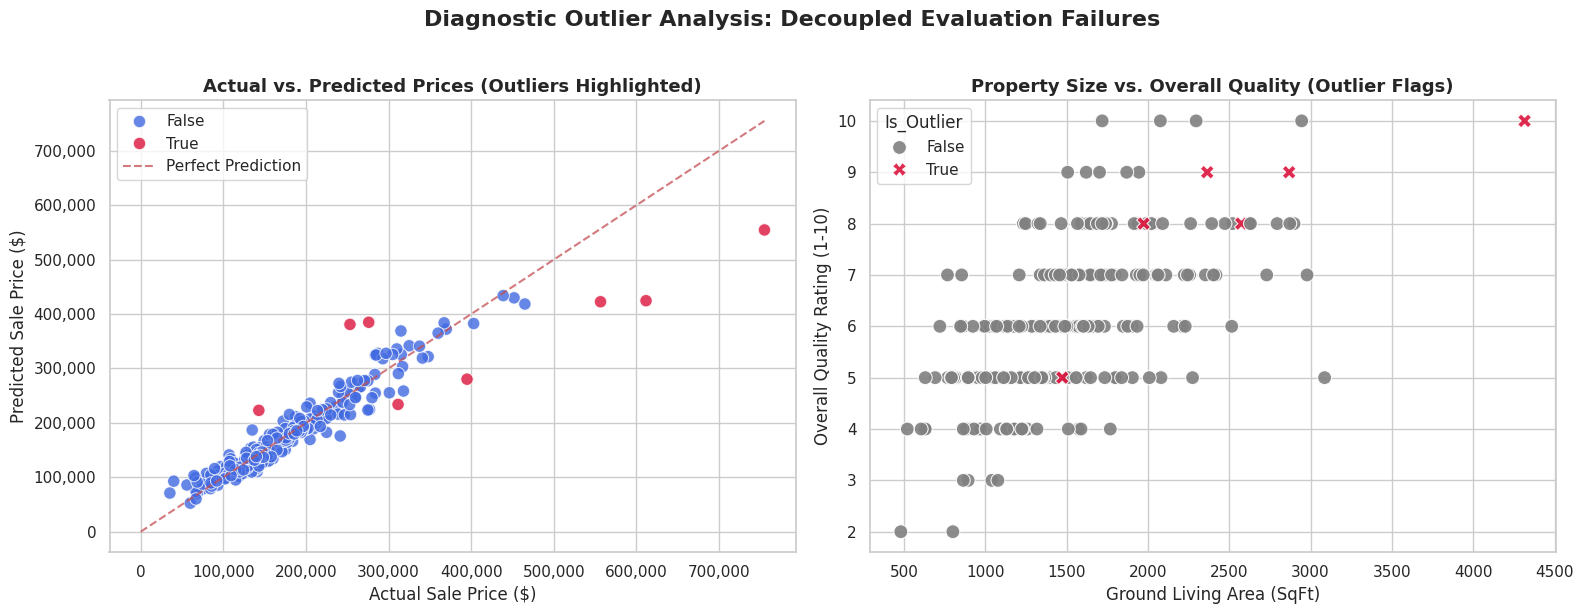

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Calculate prediction error for each test record
outlier_analysis_df = pd.DataFrame({
    'Actual_Price': y_true_dollars.astype(int),
    'Predicted_Price': y_pred_dollars.astype(int),
    'Abs_Error_Dollars': (y_pred_dollars - y_true_dollars).abs().astype(int),
    'Error_Percentage': ((y_pred_dollars - y_true_dollars) / y_true_dollars * 100).round(1),
    'OverallQual': X_test['OverallQual'],
    'GrLivArea': X_test['GrLivArea'],
    'YearBuilt': X_test['YearBuilt']
})

# Define prediction outliers as those with errors exceeding 2.5 standard deviations of the errors
std_error = outlier_analysis_df['Abs_Error_Dollars'].std()
mean_error = outlier_analysis_df['Abs_Error_Dollars'].mean()
threshold = mean_error + 2.5 * std_error

outlier_analysis_df['Is_Outlier'] = outlier_analysis_df['Abs_Error_Dollars'] > threshold

outliers = outlier_analysis_df[outlier_analysis_df['Is_Outlier']].sort_values(by='Abs_Error_Dollars', ascending=False)

print(f"Using an outlier error threshold of ${threshold:,.0f} (> Mean + 2.5 SDs):")
print(f"Identified {len(outliers)} severe prediction outliers out of {len(X_test)} test homes.\n")

print("--- Top Outliers (Worst Predictions) ---")
display(outliers)

# 2. Visualize Outliers vs Normal Predictions
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.set_theme(style="whitegrid")

# Subplot 1: Actual vs Predicted Scatter with Outliers Highlighted
sns.scatterplot(
    data=outlier_analysis_df,
    x='Actual_Price',
    y='Predicted_Price',
    hue='Is_Outlier',
    palette={False: 'royalblue', True: 'crimson'},
    alpha=0.8,
    s=80,
    ax=axes[0]
)
# Add a perfect prediction line (y = x)
lims = [0, max(outlier_analysis_df['Actual_Price'].max(), outlier_analysis_df['Predicted_Price'].max())]
axes[0].plot(lims, lims, '--r', alpha=0.75, label='Perfect Prediction')
axes[0].set_title('Actual vs. Predicted Prices (Outliers Highlighted)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Actual Sale Price ($)')
axes[0].set_ylabel('Predicted Sale Price ($)')
axes[0].get_xaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
axes[0].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda y, loc: "{:,}".format(int(y))))
axes[0].legend()

# Subplot 2: Size (GrLivArea) vs Quality colored by Outliers
sns.scatterplot(
    data=outlier_analysis_df,
    x='GrLivArea',
    y='OverallQual',
    hue='Is_Outlier',
    palette={False: 'gray', True: 'crimson'},
    s=100,
    style='Is_Outlier',
    markers={False: 'o', True: 'X'},
    alpha=0.9,
    ax=axes[1]
)
axes[1].set_title('Property Size vs. Overall Quality (Outlier Flags)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Ground Living Area (SqFt)')
axes[1].set_ylabel('Overall Quality Rating (1-10)')

plt.suptitle('Diagnostic Outlier Analysis: Decoupled Evaluation Failures', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()